# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. Тренер train_from_iterator очікує ітератор текстів. Якщо передати один рядок, Python ітеруватиме його посимвольно, тому кожен символ стане окремим текстом і жодних злиттів пар не відбудеться.
2. Нормалізація (normalization) — очищення тексту перед розбиттям: приведення до нижнього регістру, видалення акцентів, юнікод-нормалізація (NFD/NFKD), прибирання зайвих пробілів і керувальних символів.  
Попередня токенізація (pre-tokenization) — розбиття вхідного тексту на «слова» (за пробілами, пунктуацією тощо), разом із позиціями (offsets). Це задає межі, за які токени потім не виходять.  
Модель токенізації (model) — власне алгоритм, який розбиває кожне попередньо токенізоване слово на токени зі словника та перетворює їх на id. Це BPE, WordPiece або Unigram, і саме цей етап тренується на корпусі.  
Постобробка (post-processing) — додавання спецтокенів і службових даних: [CLS] на початку та [SEP] у кінці для BERT, побудова attention_mask і token_type_ids.
3. \<unk\> і \<eos\> — спеціальні токени, які ми передаємо BPE.  
\<unk\> (unknown) — токен для невідомого: ним позначається все, чого немає у словнику моделі.  
\<eos\> (end of sequence) — токен кінця послідовності. Його вставляють між віршами, щоб позначити, де закінчується один вірш і починається наступний. Завдяки цьому модель вчиться завершувати текст і не плутає кінець одного вірша з початком іншого.
4. При VOCAB_SIZE = 16000 корпус містить 18421968 токенів, при 4000 це 22362648 токенів. Середня кількість токенів на вірш зросла з 1028 до 1248. Частка <unk> в обох випадках становить 0.0%. Менший словник не підвищує частку <unk>, бо в byte-level BPE базовий алфавіт містить усі 256 байтів, тож будь-який текст можна розкласти на відомі токени. Але менший словник означає менше злиттів: слова не збираються у великі токени, а розпадаються на більше коротких шматків.
5. <eos> позначає межу між віршами — без цього при конкатенації останній токен одного вірша впритул стикається з першим токеном наступного, і модель бачить один суцільний текст замість окремих творів.
Без токена <eos> вірші в корпусі зливаються в один безперервний текст: останній токен одного вірша опиняється одразу перед першим токеном наступного, і модель вчиться передбачати початок нового вірша з кінця попереднього, хоча між ними немає жодного зв'язку, тож це шум, який псує навчання.
6. train_data і val_data — це одновимірні тензори PyTorch типу torch.int64, де кожен елемент це id токена зі словника BPE
7.
```
assert xb.shape == yb.shape == (BATCH_SIZE, CONTEXT_LEN)
assert torch.equal(xb[:, 1:], yb[:, :-1]), "y має бути x, зсунутим на один токен"
```
8. Номер рядка t це позиція поточного токена, а значення в рядку показують, які позиції  цей токен може бачити. Нижньотрикутна матриця означає, що токен на позиції t бачить лише токени 0…t, тобто себе й усі попередні. Верхньотрикутна дозволила б кожному токену бачити наступні токени, а модель має передбачати наступний токен, не знаючи його. Без маски модель під час тренування бачила б правильну відповідь, тому просто копіювала б його, і loss швидко впав би майже до нуля.
```
[[1, 0, 0, 0],
 [1, 1, 0, 0],
 [1, 1, 1, 0],
 [1, 1, 1, 1]]
```
9. Чекпоінт із найкращим val_loss і останній чекпоінт збігаються, якщо val_loss спадає аж до кінця тренування. У нашому випадку вони збігаються.
10. Крива стала інформативнішою. З'явилася початкова фаза, яку інтервал 250 пропускав: loss різко падає з 8.4 до 6.8 за перші 100 ітерацій, потім на ітераціях 250-400 падіння сповільнюється, а далі знову прискорюється. На пізніх етапах val_loss коливається на ±0.01-0.02 між сусідніми точками, бо кожна оцінка робиться лише на EVAL_ITERS = 50 випадкових батчах. Додатково це коштує 2.3 хв.
11. Температура змінює розподіл ймовірностей, за яким модель обирає наступний токен. Модель видає для кожного токена число (логіт), а температура ділить ці числа перед softmax. Чим менша температура, тим контрастніший розподіл, а чим більша, тим він рівномірніший.
Якщо температура менша за 1, модель стає передбачуванішою: найімовірніший токен отримує майже всю ймовірність. Якщо температура більша за 1, менш імовірні токени отримують більше ймовірності порівняно з найімовірнішим, тому вони частіше обираються.
Припустімо, що логіти трьох токенів дорівнюють [5, 1, 0.1]. Без температури (T = 1) ймовірності були б приблизно [0.975, 0.018, 0.007]. При T = 0.1 вони були б приблизно [1.0, 0.0, 0.0], тобто завжди обирається перший токен. При T = 20 вони були б приблизно [0.38, 0.31, 0.30], тобто розподіл майже рівномірний, і всі три токени мають схожі шанси.
Функція softmax працює так. Модель видає число для кожного токена, яке називається логітом. Щоб усі значення стали додатними, ми  беремо експоненту кожного логіта. Потім, щоб нормалізувати значення так, щоб вони в сумі давали 1, ділимо кожне з цих значень на суму всіх таких значень. З температурою ми ділимо кожен логіт на температуру перед тим, як брати експоненту. Це регулює, наскільки великі різниці між логітами: низька температура збільшує ці різниці, тому розподіл більше зосереджується на найімовірнішому токені, а висока температура зменшує їх, тому розподіл стає рівномірнішим.
12. top_p відповідає за те, з яких токенів модель обирає наступний під час генерації. Токени сортуються за ймовірністю, і залишається найменша множина найімовірніших токенів. Решта токенів відкидається, і наступний токен обирається випадково серед них.
13. Якщо поставити enable_thinking=True, модель спочатку виводить кроки своїх міркувань, і через ліміт max_new_tokens=300 ці міркування займають усі токени, тож саме продовження речення не встигає з'явитися.

In [1]:
import sys
import os
import math
import time

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Використовуємо: cuda
GPU: Tesla T4


In [3]:
from google.colab import drive

drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/University/artificial-intelligence-systems/lab3"

os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")

os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/University/artificial-intelligence-systems/lab3


In [4]:
from datasets import load_dataset

dataset = load_dataset("wikimedia/wikipedia", "20231101.uk", streaming=True)["train"]

print("Колонки:", dataset.column_names)

Колонки: ['id', 'url', 'title', 'text']


In [5]:
import pandas as pd

df = pd.DataFrame(list(dataset.take(10000)))

corpus_text = "\n\n".join(df["text"].dropna().tolist())

print("Розмір корпусу:", len(corpus_text), "символів")
print("Перші 500 символів корпусу:\n", corpus_text[:500])

Розмір корпусу: 64177973 символів
Перші 500 символів корпусу:
 Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

Поняття 
Уперше термін «географія» був запропонований давньогрецьким гео


In [6]:
words = corpus_text.split()
unique_words = set(w.lower() for w in words)

print("Слів (з повторами):   ", len(words))
print("Унікальних слів:      ", len(unique_words))
print("Приклад уривку:\n")
print(corpus_text[:500])

Слів (з повторами):    8699055
Унікальних слів:       876758
Приклад уривку:

Геогра́фія, або заст. земле́пис (від  — опис Землі; де  — Земля і  — писати, описувати) — система наук, що вивчає географічну оболонку Землі (епігеосферу), її просторову природну і соціально-економічну різноманітність, господарство і населення планети, окремих її регіонів та країн, а також зв'язки між природним середовищем і діяльністю людини. В сучасному розумінні поняття «географія» заміщено поняттям «географічні науки».

Поняття 
Уперше термін «географія» був запропонований давньогрецьким гео


In [7]:
import re

_BAD = re.compile(r"[^0-9A-Za-zА-Яа-яЇїІіЄєҐґ'’ʼ\s.,;:!?…\-–—«»“”\"()%/№]")

def clean_text(text):
    text = _BAD.sub("", text)
    text = re.sub(r"[ \t]+", " ", text)
    return text.strip()

docs = [clean_text(t)[:6000] for t in df["text"].dropna()]

In [8]:
from transformers import AutoTokenizer

base_tokenizer = AutoTokenizer.from_pretrained("Qwen/Qwen2.5-0.5B-Instruct")
new_tokenizer = base_tokenizer.train_new_from_iterator(docs[:3000], vocab_size=5000)

sample = "Київ — столиця України, місто на березі Дніпра."

print("Original Qwen2.5:", len(base_tokenizer.tokenize(sample)), "tokens:", base_tokenizer.tokenize(sample))
print("Retrained (vocab_size=5000):", len(new_tokenizer.tokenize(sample)), "tokens:", new_tokenizer.tokenize(sample))

Original Qwen2.5: 26 tokens: ['Ðļ', 'Ð¸', 'ÑĹ', 'Ð²', 'ĠâĢĶ', 'ĠÑģÑĤÐ¾Ð»', 'Ð¸', 'ÑĨ', 'Ñı', 'ĠÐ£ÐºÑĢÐ°', 'ÑĹ', 'Ð½Ð¸', ',', 'ĠÐ¼', 'Ñĸ', 'ÑģÑĤÐ¾', 'ĠÐ½Ð°', 'ĠÐ±ÐµÑĢ', 'ÐµÐ·', 'Ñĸ', 'ĠÐĶ', 'Ð½', 'Ñĸ', 'Ð¿', 'ÑĢÐ°', '.']
Retrained (vocab_size=5000): 14 tokens: ['Ðļ', 'Ð¸ÑĹÐ²', 'ĠâĢĶ', 'ĠÑģÑĤÐ¾Ð»Ð¸', 'ÑĨÑı', 'ĠÐ£ÐºÑĢÐ°ÑĹÐ½Ð¸', ',', 'ĠÐ¼ÑĸÑģÑĤÐ¾', 'ĠÐ½Ð°', 'ĠÐ±ÐµÑĢÐµÐ·', 'Ñĸ', 'ĠÐĶÐ½ÑĸÐ¿', 'ÑĢÐ°', '.']


In [9]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, normalizers, decoders

VOCAB_SIZE = 500

UNKNOWN_TOKEN="<unk>"
PADDING_TOKEN="<pad>"

SPECIALS = [UNKNOWN_TOKEN, PADDING_TOKEN]

train_sample = docs[:1000]
eval_sample = docs[1000:1200]

def create_model(model):
    tokenizer = Tokenizer(model)
    tokenizer.normalizer = normalizers.NFC()
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    return tokenizer

bpe_compare = create_model(models.BPE(unk_token=UNKNOWN_TOKEN))
bpe_compare.train_from_iterator(train_sample, trainers.BpeTrainer(vocab_size=VOCAB_SIZE, special_tokens=SPECIALS))

word_piece_compare = create_model(models.WordPiece(unk_token=UNKNOWN_TOKEN))
word_piece_compare.decoder = decoders.WordPiece(prefix="##")
word_piece_compare.train_from_iterator(train_sample, trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE, special_tokens=SPECIALS, continuing_subword_prefix="##"))

unigram_compare = create_model(models.Unigram())
unigram_compare.train_from_iterator(train_sample, trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE, special_tokens=SPECIALS, unk_token=UNKNOWN_TOKEN))

compare_tokenizers = {
    "BPE": bpe_compare,
    "WordPiece": word_piece_compare,
    "Unigram": unigram_compare
}

for name, tokenizer in compare_tokenizers.items():
    print(f"{name:10s} vocab: {tokenizer.get_vocab_size()}")

BPE        vocab: 500
WordPiece  vocab: 500
Unigram    vocab: 500


In [10]:
from collections import Counter

counter = Counter(word for d in train_sample for word in d.split())

eval_words = [word for d in eval_sample for word in d.split() if word.isalpha()]
frequent_word = next(w for w, _ in counter.most_common() if len(w) >= 6 and w.isalpha())
rare_word = max((w for w in set(eval_words) if counter[w] == 0), key=len)

TEST_WORDS = {
    "frequent": frequent_word,
    "rare": rare_word,
    "own 1": "Україна",
    "own 2": "електроенцефалографія"
}

n_words = sum(len(d.split()) for d in eval_sample)

rows = []

for name, t in compare_tokenizers.items():
    encs = t.encode_batch(eval_sample)

    n_tok = sum(len(e.ids) for e in encs)
    n_unk = sum(e.ids.count(t.token_to_id(UNKNOWN_TOKEN)) for e in encs)

    row = {
        "algorithm": name,
        "vocab": t.get_vocab_size(),
        "tokens (sample)": n_tok,
        "tokens/word": round(n_tok / n_words, 3),
        UNKNOWN_TOKEN + ", %": round(100 * n_unk / n_tok, 3)
    }

    for label, word in TEST_WORDS.items():
        row[f"{label}: {word}"] = " | ".join(t.encode(word).tokens)

    rows.append(row)

compare_difference = pd.DataFrame(rows)

display(compare_difference.iloc[:, :5])

for label, word in TEST_WORDS.items():
    print(f"\n- {label}: {word}")

    for row in rows:
        print(f"   {row['algorithm']:10s}", row[f"{label}: {word}"])

,algorithm,vocab,tokens (sample),tokens/word,"<unk>, %"
0,BPE,500,498490,3.666,0.000
1,WordPiece,500,569000,4.184,0.001
2,Unigram,500,531407,3.908,0.000



- frequent: український
   BPE        український
   WordPiece  український
   Unigram    українськ | ий

- rare: внутрішньоконтинентальних
   BPE        в | ну | т | рі | ш | н | ь | о | кон | ти | н | ен | та | ль | них
   WordPiece  в | ##ну | ##т | ##рі | ##ш | ##н | ##ь | ##ок | ##он | ##т | ##ин | ##ент | ##аль | ##них
   Unigram    в | н | у | т | рі | ш | нь | о | кон | ти | н | ен | та | ль | них

- own 1: Україна
   BPE        Украї | на
   WordPiece  Украї | ##на
   Unigram    Україн | а

- own 2: електроенцефалографія
   BPE        е | ле | к | тро | ен | це | ф | а | л | ог | ра | ф | ія
   WordPiece  е | ##л | ##ек | ##т | ##р | ##о | ##ен | ##ц | ##е | ##ф | ##ал | ##ог | ##ра | ##ф | ##ія
   Unigram    е | ле | к | тро | ен | це | ф | а | л | ограф | і | я


In [11]:
ranked = compare_difference.sort_values("tokens/word").reset_index(drop=True)

best = ranked.iloc[0]
worst = ranked.iloc[-1];

print("Ranking by tokens per word (fewer = shorter sequences):")

for _, r in ranked.iterrows():
    print(f"  {r['algorithm']:10s} {r['tokens/word']:.3f} tokens/word | {r['tokens (sample)']} tokens | {UNKNOWN_TOKEN} {r[UNKNOWN_TOKEN + ", %"]}%")

print(f"\nShortest sequences: {best['algorithm']} ({best['tokens/word']:.3f} tokens/word)")
print(f"Longest sequences:  {worst['algorithm']} ({worst['tokens/word']:.3f} tokens/word)")

Ranking by tokens per word (fewer = shorter sequences):
  BPE        3.666 tokens/word | 498490 tokens | <unk> 0.0%
  Unigram    3.908 tokens/word | 531407 tokens | <unk> 0.0%
  WordPiece  4.184 tokens/word | 569000 tokens | <unk> 0.001%

Shortest sequences: BPE (3.666 tokens/word)
Longest sequences:  WordPiece (4.184 tokens/word)


Найкоротші послідовності дав BPE: 3.666 токена на слово. Unigram трохи довший, 3.908, а найдовший WordPiece, 4.184.
З туторіалом це в цілому сходиться. BPE на кожному кроці зливає найчастішу пару токенів, тому в словнику швидко з'являються цілі часті слова: наприклад, «український» у нього один токен. Унiграм починає з великого словника й викидає токени, які найменше впливають на втрату, а слово ріже за алгоритмом Віттербі на найімовірніші шматки, тобто зазвичай на якомога менше токенів. Тут «український» він розбив на два (`українськ | ий`), тому вийшло трохи довше, ніж у BPE, але різниця невелика.
WordPiece дав найдовші послідовності. Як описано в туторіалі, він обирає пару для злиття не за найвищою частотою, а за оцінкою `freq(пари) / (freq(a) · freq(b))`, тобто віддає перевагу парам, частини яких рідко трапляються окремо. Тому часті короткі шматки довше лишаються незлитими. До того ж токенізує він жадібно, шукаючи найдовший підрядок зі словника від початку слова, і тому рідкісне слово «внутрішньоконтинентальних» він порізав на ≈14 частин з префіксами `##`, а BPE та Unigram приблизно на 15 коротких шматків без префіксів, тож для рідкісних слів різниці майже немає.

In [12]:
import json
import numpy as np
import pandas as pd
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders
from torch.utils.tensorboard import SummaryWriter

SEED = 42
torch.manual_seed(SEED)

MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
os.makedirs(MODELS_DIR, exist_ok=True)
RESULTS_PATH = os.path.join(ARTIFACT_DIR, "results.csv")

_results = {}

if os.path.exists(RESULTS_PATH):
    for _r in pd.read_csv(RESULTS_PATH).to_dict("records"):
        _results[(_r["section"], _r["name"], _r["metric"])] = _r

def log_result(section, name, metric, value, **details):
    _results[(str(section), str(name), str(metric))] = dict(
        section=str(section), name=str(name), metric=str(metric), value=value,
        details=json.dumps(details, ensure_ascii=False, default=str))
    pd.DataFrame(list(_results.values())).to_csv(RESULTS_PATH, index=False)

def free_memory():
    import gc
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

_data_cache = {}

def train_bpe_tokenizer(texts, vocab_size):
    tok = Tokenizer(models.BPE(unk_token="<unk>"))
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["<unk>", "<eos>"],
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet())
    tok.train_from_iterator(texts, trainer=trainer)
    return tok

def encode_corpus(tok, texts, batch_size=1000):
    eos_id = tok.token_to_id("<eos>")
    chunks = []
    for i in range(0, len(texts), batch_size):
        for enc in tok.encode_batch(texts[i:i + batch_size]):
            chunks.append(np.array(enc.ids + [eos_id], dtype=np.int32))
    ids = np.concatenate(chunks)
    del chunks
    return torch.from_numpy(ids.astype(np.int64))

def get_data(vocab_size):
    """-> (tokenizer, data, chars_per_token)"""
    if vocab_size not in _data_cache:
        tok = train_bpe_tokenizer(docs, vocab_size)
        data = encode_corpus(tok, docs)
        cpt = sum(len(d) for d in docs) / len(data)
        unk_share = (data == tok.token_to_id("<unk>")).float().mean().item()
        print(f"vocab={vocab_size}: tokens {len(data):,} | <unk> {unk_share:.3%} | chars/token {cpt:.2f}")
        _data_cache[vocab_size] = (tok, data, cpt)
    return _data_cache[vocab_size]

In [13]:
class AttentionHead(nn.Module):
    def __init__(self, embed_dim: int, head_dim: int, context_len: int, dropout: float):
        super().__init__()
        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)
        self.dropout = nn.Dropout(dropout)
        causal_mask = torch.tril(torch.ones(context_len, context_len))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        scores = q @ k.transpose(-2, -1) / math.sqrt(k.shape[-1])
        scores = scores.masked_fill(self.causal_mask[:T, :T] == 0, float("-inf"))
        weights = F.softmax(scores, dim=-1)
        weights = self.dropout(weights)

        return weights @ v

In [14]:
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        head_dim = embed_dim // n_heads
        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, context_len, dropout) for _ in range(n_heads)
        ])
        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout= nn.Dropout(dropout)

    def forward(self, x):
        results = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(results))


In [15]:
class FeedForward(nn.Module):
    def __init__(self, embed_dim: int, dropout: float):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

class TransformerBlock(nn.Module):
    def __init__(self, embed_dim: int, n_heads: int, context_len: int, dropout: float):
        super().__init__()
        self.attention = MultiHeadAttention(embed_dim, n_heads, context_len, dropout)
        self.feed_forward = FeedForward(embed_dim, dropout)
        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x

In [16]:
class MiniGPT(nn.Module):
    def __init__(self, vocab_size: int, embed_dim: int, n_heads: int, n_layers: int,
                 context_len: int, dropresults: float):
        super().__init__()
        self.context_len = context_len
        self.token_embedding = nn.Embedding(vocab_size, embed_dim)
        self.position_embedding = nn.Embedding(context_len, embed_dim)
        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, context_len, dropresults) for _ in range(n_layers)
        ])
        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding(idx)
        pos_emb = self.position_embedding(torch.arange(T, device=idx.device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.shape[-1]), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens: int, temperature: float = 1.0,
                 top_k: int | None = None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
        return idx


In [17]:
BASE = dict(vocab_size=8000, context_len=64, embed_dim=128, n_heads=4, n_layers=4, dropresults=0.1,
            batch_size=64, lr=3e-4, max_iters=10000, eval_interval=500, eval_iters=30)

VARIANTS = {
    "v1": dict(BASE, tag="baseline"),
    "v2": dict(BASE, vocab_size=4000, tag="vocab4000"),
    "v3": dict(BASE, context_len=128, tag="ctx128"),
    "v4": dict(BASE, n_layers=6, tag="layers6"),
}

RETRAIN = False

def train_variant(vid, cfg):
    tok, data, cpt = get_data(cfg["vocab_size"])
    split_idx = int(len(data) * 0.9)
    train_data, val_data = data[:split_idx], data[split_idx:]
    ctx, bs = cfg["context_len"], cfg["batch_size"]

    def get_batch(split):
        source = train_data if split == "train" else val_data
        ix = torch.randint(len(source) - ctx - 1, (bs,))
        x = torch.stack([source[i:i + ctx] for i in ix])
        y = torch.stack([source[i + 1:i + ctx + 1] for i in ix])
        return x.to(device), y.to(device)

    torch.manual_seed(SEED)
    model = MiniGPT(tok.get_vocab_size(), cfg["embed_dim"], cfg["n_heads"], cfg["n_layers"], ctx, cfg["dropresults"]).to(device)
    n_params = sum(p.numel() for p in model.parameters())
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg["lr"])
    run_name = f"minigpt_{vid}_{cfg['tag']}_vocab{cfg['vocab_size']}_ctx{ctx}_L{cfg['n_layers']}_H{cfg['n_heads']}"
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, run_name))
    ckpt_path = os.path.join(MODELS_DIR, f"minigpt_{vid}.pt")

    @torch.no_grad()
    def estimate_loss():
        model.eval()
        results = {}

        for sp in ("train", "val"):
            losses = torch.zeros(cfg["eval_iters"])

            for i in range(cfg["eval_iters"]):
                xb, yb = get_batch(sp)
                losses[i] = model(xb, yb)[1].item()

            results[sp] = losses.mean().item()

        model.train()
        return results

    hist = dict(iters=[], train=[], val=[])
    best_val, best_iter = float("inf"), None
    t0 = time.time()
    print(f"\n=== {vid} ({cfg['tag']}) | params: {n_params:,} | {run_name} ===")

    for it in range(cfg["max_iters"]):
        xb, yb = get_batch("train")
        _, loss = model(xb, yb)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        if it % cfg["eval_interval"] == 0 or it == cfg["max_iters"] - 1:
            losses = estimate_loss()
            hist["iters"].append(it); hist["train"].append(losses["train"]); hist["val"].append(losses["val"])
            writer.add_scalar("Loss/train", losses["train"], it)
            writer.add_scalar("Loss/val", losses["val"], it)
            print(f"iter {it:5d}  train={losses['train']:.3f}  val={losses['val']:.3f}  ({(time.time() - t0) / 60:.1f} min)")
            if losses["val"] < best_val:
                best_val, best_iter = losses["val"], it
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    writer.close()

    minutes = (time.time() - t0) / 60

    info = dict(vid=vid, cfg=cfg, n_params=n_params, best_val_loss=best_val, best_iter=best_iter,
                val_bpc=best_val / math.log(2) / cpt, chars_per_token=cpt, minutes=minutes, hist=hist)

    torch.save(dict(state_dict=best_state, tokenizer_json=tok.to_str(), **info), ckpt_path)
    print(f"Done in {minutes:.1f} min | best val_loss={best_val:.3f} (iter {best_iter})")
    del model, optimizer
    free_memory()

    return info

trained = {}

for vid, cfg in VARIANTS.items():
    path = os.path.join(MODELS_DIR, f"minigpt_{vid}.pt")

    if os.path.exists(path) and not RETRAIN:
        ck = torch.load(path, map_location="cpu")
        trained[vid] = {k: v for k, v in ck.items() if k not in ("state_dict", "tokenizer_json")}
        print(f"{vid}: checkpoint exists, skipping")

    else:
        trained[vid] = train_variant(vid, cfg)

    t = trained[vid]

    log_result("3.2", vid, "val_loss", round(t["best_val_loss"], 4), tag=t["cfg"]["tag"],
               val_bpc=round(t["val_bpc"], 4), n_params=t["n_params"], best_iter=t["best_iter"],
               **{k: t["cfg"][k] for k in ("vocab_size", "context_len", "n_layers", "n_heads", "max_iters")})

v1: checkpoint exists, skipping
v2: checkpoint exists, skipping
v3: checkpoint exists, skipping
v4: checkpoint exists, skipping


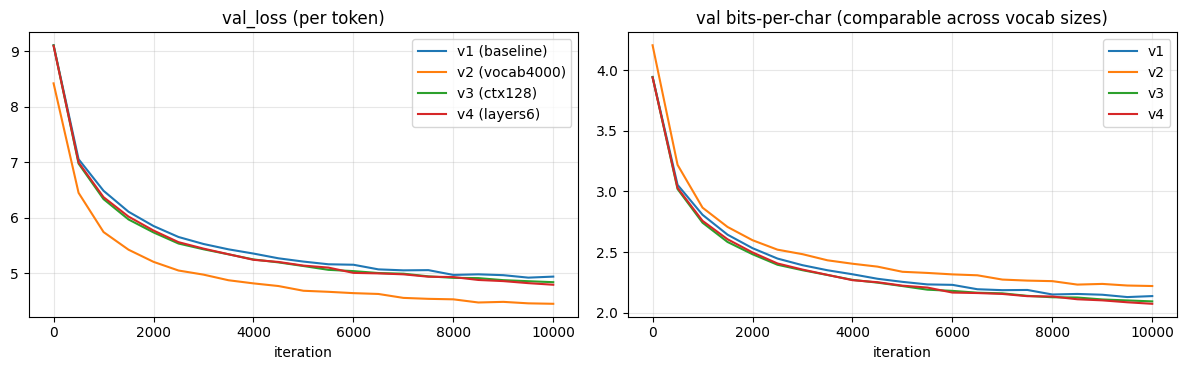

,variant,tag,vocab,ctx,layers,params,best_iter,val_loss,val_bpc
3,v4,layers6,8000,64,6,3251776,9999,4.794,2.076
2,v3,ctx128,8000,128,4,2864192,9999,4.840,2.095
0,v1,baseline,8000,64,4,2856000,9500,4.922,2.131
1,v2,vocab4000,4000,64,4,1828000,9999,4.451,2.222


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

for vid, t in trained.items():
    h = t["hist"]
    axes[0].plot(h["iters"], h["val"], label=f"{vid} ({t['cfg']['tag']})")
    axes[1].plot(h["iters"], np.array(h["val"]) / math.log(2) / t["chars_per_token"], label=vid)

axes[0].set_title("val_loss (per token)")
axes[1].set_title("val bits-per-char (comparable across vocab sizes)")

for ax in axes:
    ax.set_xlabel("iteration"); ax.grid(alpha=0.3); ax.legend()

plt.tight_layout()
plt.show()

summary = pd.DataFrame([{
    "variant": vid, "tag": t["cfg"]["tag"], "vocab": t["cfg"]["vocab_size"], "ctx": t["cfg"]["context_len"],
    "layers": t["cfg"]["n_layers"], "params": t["n_params"], "best_iter": t["best_iter"],
    "val_loss": round(t["best_val_loss"], 3), "val_bpc": round(t["val_bpc"], 3)}
    for vid, t in trained.items()]).sort_values("val_bpc")

display(summary)

In [19]:
PROMPT = "Київ — столиця"

def generate_from_variant(vid, prompt, max_new_tokens=60, temperature=0.8, top_k=40, seed=SEED):
    ck = torch.load(os.path.join(MODELS_DIR, f"minigpt_{vid}.pt"), map_location=device)
    c = ck["cfg"]
    tok = Tokenizer.from_str(ck["tokenizer_json"])
    m = MiniGPT(tok.get_vocab_size(), c["embed_dim"], c["n_heads"], c["n_layers"], c["context_len"], c["dropout"]).to(device)
    m.load_state_dict(ck["state_dict"])
    ids = torch.tensor([tok.encode(prompt).ids], dtype=torch.long, device=device)
    torch.manual_seed(seed)
    results = m.generate(ids, max_new_tokens, temperature=temperature, top_k=top_k)
    text = tok.decode(results[0].tolist())
    del m
    return text

for vid, t in trained.items():
    print(f"=== {vid} ({t['cfg']['tag']}) | iter {t['best_iter']} | val_loss={t['best_val_loss']:.3f} ===")
    print(generate_from_variant(vid, PROMPT))
    print()
free_memory()

=== v1 (baseline) | iter 9500 | val_loss=4.922 ===
Київ — столиця у складі Галичини та М. Л. Ф. — Сик. — Тернопіль: В. Г. Р. П. Г. Р. Жест. П. В. Пов. Ритов. В.

=== v2 (vocab4000) | iter 9999 | val_loss=4.451 ===
Київ — столиця Фауда
 Маймана
 Потоцька диктська

Народились

Померли 

130-тіВисоке Середньовіччя Золота доба ісламу Реконкіста Хрестові

Геополітична ситуація 

Ресятиліття
Міста

=== v3 (ctx128) | iter 9999 | val_loss=4.840 ===
Київ — столиця Фаула.

У світі 
 13 вересня — Аліна (на Гілю) в Брадіана (Рах) у битві біля Гаспіт.

Народились

Померли

Див. також 
 Список керівників держав 360-ті
380

=== v4 (layers6) | iter 9999 | val_loss=4.794 ===
Київ — столиця у складі Тогонського.

Під час Другої світової війни він працював у Гілла закордонних лічжем Т. І. Калаґо-Романз, а також направила війну з Дарком та К. С. Матенко



За `val_loss` найкращий v2 (словник 4000): 4.451 проти 4.8–4.9 в інших. За бітами на символ (bpc): v4 (6 шарів) 2.076, v3 (контекст 128) 2.095, baseline v1 2.131, а v2 найгірший, 2.222. Тож за чесною метрикою кращий варіант v4. Від v3 його відділяє лише 0.019 bpc.
У згенерованому тексті різниця між варіантами помітна, хоч і не повністю збігається з метриками. v3 і v4 пишуть повні речення: v3 вчить формат статей Вікіпедії («13 вересня — … у битві біля …», розділи «Народились», «Померли», «Див. також»), а v4 видає найзв'язніший текст («Під час Другої світової війни він працював у … лікарем»), хоча імена й факти вигадані. v1 застряг на переліках ініціалів («В. Г. Р. П. Г. Р.»). v2, з найменшим словником і найгіршим bpc, видає переважно заголовки й короткі рядки («Геополітична ситуація», «Міста») замість речень.
Найбільший вплив дала зміна словника: зменшення з 8000 до 4000 погіршило bpc на ≈0.09 відносно baseline (при цьому модель стала меншою, 1.8 млн параметрів проти 2.9 млн). Збільшення кількості шарів з 4 до 6 покращило bpc на ≈0.055 (3.3 млн параметрів), а подовження контексту з 64 до 128 на ≈0.036 майже без збільшення моделі. Криві всіх варіантів до кінця тренування ще повільно спадали (`best_iter` близько 9999), тож довше тренування дало б ще трохи кращий результат. Щоб упевнено розрізнити v3 і v4, потрібно кілька запусків з різними seed.

In [20]:
!pip install "transformers[sentencepiece]==5.18.0"

In [21]:
from transformers import pipeline

# Sentiment analysis
classifier = pipeline("sentiment-analysis")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier("I hate this so much!"))

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [22]:
from transformers import pipeline

# Zero-shot classification
classifier = pipeline("zero-shot-classification")
classifier(
    "This is a course abresults the Transformers library",
    candidate_labels=["education", "politics", "business"],
)

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course abresults the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.6486154794692993, 0.24881722033023834, 0.10256732255220413]}

In [23]:
from transformers import pipeline

# Text generation
generator = pipeline("text-generation", model="distilgpt2")
print(generator("In this course, we will teach you how to"))

generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_length=30,
    num_return_sequences=2,
))

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

... (4 outputs left out)

[{'generated_text': 'In this course, we will teach you how to get a better understanding of the techniques and techniques employed by the C++ community. This course is for the first time.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n'}]


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': "In this course, we will teach you how to use this material in your own practice. We'll teach you how to use this material in your own practice.\n\n\n\nThe main thing to do here is to use your own terminology. Your own words will be used in terms of the meaning of the words as they are used.\nI will provide you with the following instructions:\n1. When you start using the word in your own practice, you will only use the word 'a' if you use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' if you use it.\n2. When you start using the word in your own practice, you will only use the word 'a' if you use it. This is the last time you use it, and you will only use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' when you are using it. This is the last time you use it, and you will only use the word 'a' when you are using it.\n3. When you start using the word in y

In [24]:
from transformers import pipeline

# Fill-mask
unmasker = pipeline("fill-mask")
unmasker("This course will teach you all abresults <mask> models.", top_k=2)

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.bias   | UNEXPECTED |  | 
roberta.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.038712527602910995,
  'token': 39974,
  'token_str': ' regression',
  'sequence': 'This course will teach you all abresults regression models.'},
 {'score': 0.03732286021113396,
  'token': 27774,
  'token_str': 'arial',
  'sequence': 'This course will teach you all abresultsarial models.'}]

In [25]:
from transformers import pipeline

# Named entity recognition
ner = pipeline("ner", aggregation_strategy="simple")
ner("My name is Sylvain and I work at Hugging Face in Brooklyn.")

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [26]:
from transformers import pipeline

# Question answering
question_answerer = pipeline("table-question-answering")
question_answerer(
    query="How many stars does the transformers repository have?",
    table={
        "Repository": ["Transformers", "Datasets", "Tokenizers"],
        "Stars":["36542","4512","3934"],
        "Contributors":["651","77","34"],
        "Programming language":["Python","Python","Rust, Python and NodeJS"]
    },
)

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

**Українськомовні приклади**

In [27]:
from transformers import pipeline

# Sentiment analysis
classifier = pipeline(
    "text-classification",
    model="tabularisai/multilingual-sentiment-analysis"
)

print(classifier("Мені дуже подобається цей курс! Я дізнався багато нового."))
print(classifier("Я дуже розчарований результатом."))
print(classifier("Сьогодні жахливий день. У мене нічого не виходить."))

config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.20k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

[{'label': 'Positive', 'score': 0.8188588619232178}]
[{'label': 'Negative', 'score': 0.7173140645027161}]
[{'label': 'Very Negative', 'score': 0.8687207102775574}]


In [28]:
from transformers import pipeline

# Zero-shot classification
classifier = pipeline("zero-shot-classification", model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli")
classifier(
    "Цей курс допомагає студентам вивчати програмування.",
    candidate_labels=["освіта", "спорт", "медицина"],
)

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 4.31MB            

... (2 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

{'sequence': 'Цей курс допомагає студентам вивчати програмування.',
 'labels': ['освіта', 'медицина', 'спорт'],
 'scores': [0.9965911507606506, 0.001779292244464159, 0.0016295844689011574]}

In [29]:
from transformers import pipeline

# Text generation
generator = pipeline("text-generation", model="malteos/gpt2-uk")
print(generator("Одного разу я вирішив вирушити в подорож"))

print(generator(
    "Сьогодні в університеті студенти дізналися",
    max_length=30,
    num_return_sequences=2,
))

config.json:   0%|          | 0.00/958 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  511MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

[transformers] GPT2LMHeadModel LOAD REPORT from: malteos/gpt2-uk
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
transformer.h.{0...11}.attn.masked_bias | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/344 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.84M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/96.0 [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=256) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


[{'generated_text': 'Одного разу я вирішив вирушити в подорож на схід, щоб дізнатися, чи був у мене в країні звичайнісінький джиг! Як його там шукати? І коли ми зустрілися, і він мені відповів, щоб я не хотів їхати додому, я пішов на північ. Через тиждень я був уже в дорозі, і це було в перший раз. Як тільки я повернувся з відрядження, я знайшов собі роботу. Я сказав, що це справа серйозна, і хотів би знайти роботу в іншому місті, але я сказав, що хочу відкрити це в іншій країні.\nДієта для схуднення. Відтепер, щоб схуднути, достатньо всього 3 хвилин, щоб схуднути на пару кілограмів і з’їсти. Якщо ви не знаєте, як готувати цю страву, спробуйте приготувати цю страву на своїй кухні. Але пам’ятайте, що це не так. Для людей, які не мають проблем зі шлунком і кишечником, ця страва повинна бути набагато правильнішою, ніж для людей з проблемною травленням. Саме тому, щоб приготувати цю страву, вам потрібно не менше, ніж 4 години, на той самий стіл, готувати до обіду або вечерю. Не секрет, що 

In [30]:
from transformers import pipeline

# Fill-mask
unmasker = pipeline("fill-mask", model="ukr-models/xlm-roberta-base-uk")
unmasker("Київ — столиця <mask>.", top_k=2)

config.json:   0%|          | 0.00/711 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B /  854kB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

[{'score': 0.45024290680885315,
  'token': 1702,
  'token_str': 'України',
  'sequence': 'Київ — столиця України .'},
 {'score': 0.09045535326004028,
  'token': 5,
  'token_str': '.',
  'sequence': 'Київ — столиця. .'}]

In [31]:
from transformers import pipeline

# Named entity recognition
ner = pipeline("ner", model="ukr-models/uk-ner", aggregation_strategy="simple")
ner("Мене звати Олексій, я працюю в Google у Києві.")

config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.37M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.99996686),
  'word': 'Олексій',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9944629),
  'word': 'Google',
  'start': 31,
  'end': 37},
 {'entity_group': 'LOC',
  'score': np.float32(0.99998605),
  'word': 'Києві',
  'start': 40,
  'end': 45}]

In [32]:
!pip install -q evaluate scikit-learn

import time, evaluate, pandas as pd
from transformers import pipeline

data = [
    ("Мені дуже сподобався фільм!", 1),
    ("Фільм був цікавим і захопливим.", 1),
    ("Я дуже задоволений покупкою!", 1),
    ("Дуже приємна атмосфера та чудова музика.", 1),
    ("Персонал був привітним і уважним.", 1),
    ("Результат перевершив усі мої очікування!", 1),
    ("Це найкращий ресторан, у якому я був!", 1),
    ("Я із задоволенням рекомендую цей заклад!", 1),
    ("Чудова якість за доступною ціною!", 1),
    ("Це був неймовірний досвід!", 1),
    ("Жахливий сервіс, більше не прийду.", 0),
    ("Мені зовсім не сподобалося обслуговування.", 0),
    ("Їжа була холодною та несмачною.", 0),
    ("Цей товар виявився повним розчаруванням.", 0),
    ("Обслуговування було повільним і неприємним.", 0),
    ("Якість товару просто жахлива.", 0),
    ("Більше ніколи не замовлятиму тут.", 0),
    ("Мій день був зіпсований через цей сервіс.", 0),
    ("Даремно витрачені гроші та час.", 0),
    ("Абсолютно незадоволений отриманою послугою.", 0),

    ("Не можу сказати, що мені не сподобалось, навпаки, у захваті.", 1),
    ("Спочатку було важко, але результат перевершив усі очікування.", 1),
    ("Нічого особливого, але й нарікати не буду.", 1),
    ("Гарна ідея, але реалізація повна катастрофа.", 0),
    ("Ой, чудово, знову відключили світло, просто щастя.", 0),
    ("Ну дякую, дуже допомогли, тепер нічого не працює.", 0),
]

texts = [text for text, _ in data]
labels = [label for _, label in data]

In [33]:
accuracy = evaluate.load("accuracy")
f1 = evaluate.load("f1")

def test(model_id):
    classification = pipeline("text-classification", model=model_id)

    start = time.time()
    result = classification(texts)
    finish = time.time()

    difference = finish - start

    preds = [1 if "pos" in o["label"].lower() else 0 for o in result]

    return {
        "model": model_id,
        "accuracy": round(accuracy.compute(predictions=preds, references=labels)["accuracy"], 2),
        "f1": round(f1.compute(predictions=preds, references=labels)["f1"], 2),
        "seconds": round(difference, 2),
        "params": sum(p.numel() for p in classification.model.parameters()),
    }

results = [
    test("tabularisai/multilingual-sentiment-analysis"),
    test("cardiffnlp/twitter-xlm-roberta-base-sentiment"),
    test("lxyuan/distilbert-base-multilingual-cased-sentiments-student")
]

pd.DataFrame(results)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (9 outputs left out)

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

,model,accuracy,f1,seconds,params
0,tabularisai/multilingual-sentiment-analysis,0.85,0.83,0.61,135328517
1,cardiffnlp/twitter-xlm-roberta-base-sentiment,0.88,0.89,1.80,278045955
2,lxyuan/distilbert-base-multilingual-cased-sent...,0.65,0.57,0.39,135326979


In [34]:
from transformers import pipeline

best = "cardiffnlp/twitter-xlm-roberta-base-sentiment"
classification = pipeline("text-classification", model=best, top_k=None)

results = classification(texts)

probabilities = [sum(d["score"] for d in scores if "pos" in d["label"].lower())
    for scores in results]

rows = []

for threshold in [0.3, 0.5, 0.7, 0.9]:
    preds = [1 if probability > threshold else 0 for probability in probabilities]

    rows.append({
        "threshold": threshold,
        "accuracy": round(accuracy.compute(predictions=preds, references=labels)["accuracy"], 2),
        "f1": round(f1.compute(predictions=preds, references=labels)["f1"], 2),
    })

print("Model: ", best)
pd.DataFrame(rows)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Model:  cardiffnlp/twitter-xlm-roberta-base-sentiment


,threshold,accuracy,f1
0,0.3,0.88,0.89
1,0.5,0.88,0.89
2,0.7,0.81,0.80
3,0.9,0.62,0.44


Найкращою моделлю виявилась cardiffnlp/twitter-xlm-roberta-base-sentiment
(accuracy 0.88, F1 0.89). Найкращий результат (accuracy 0.88, F1 0.89) дали пороги 0.3 і 0.5. Підвищення порогу до 0.7 погіршило результат (F1 впало з 0.89 до 0.80), а при 0.9 модель стала надто обережною: вона почала відносити до позитивних лише речення, у яких майже стовідсотково впевнена, тому частина справді позитивних речень стала «негативними», і F1 впав до 0.44.

In [35]:
!pip install -q gradio

In [36]:
import gradio as gr
from transformers import pipeline, set_seed

generator = pipeline("text-generation", model="distilgpt2")

def generate(prompt, max_new_tokens, temperature, top_k, top_p):
    if not prompt.strip():
        return "Enter some text first."

    output = generator(
        prompt,
        max_new_tokens=int(max_new_tokens),
        do_sample=True,
        temperature=float(temperature),
        top_k=int(top_k),
        top_p=float(top_p),
        pad_token_id=generator.tokenizer.eos_token_id,
    )

    return output[0]["generated_text"]

demo = gr.Interface(
    fn=generate,
    inputs=[
        gr.Textbox(label="Text", lines=3, value="In this course, we will teach you how to"),
        gr.Slider(5, 200, value=50, step=5, label="max_new_tokens (length of the continuation)"),
        gr.Slider(0.1, 2.0, value=1.0, step=0.1, label="temperature (higher = more random)"),
        gr.Slider(1, 200, value=50, step=1, label="top_k (sample only from the k most likely words)"),
        gr.Slider(0.1, 1.0, value=1, step=0.05, label="top_p (sample from the smallest set with this total probability)"),
    ],
    outputs=gr.Textbox(label="Generated text", lines=12),
)

demo.launch()

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://5eedc7334199234c10.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
